# Практическая работа 1

Я решил выбрать компанию NVIDIA и взять данные у Yahoo Finance:

- период: 5 лет
- частота: месячная
- основной ряд для прогноза: close
- дополнительные ряды: open, high, low, volume


## 1. Анализ исходных данных


Библиотека для загрузки биржевых данных


In [33]:
%pip install yfinance pandas matplotlib


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


Загрузим сами данные согласно условию

In [34]:
import yfinance as yf

nvda = yf.Ticker("NVDA")

data = nvda.history(
    period="5y",
    interval="1mo",
    auto_adjust=False)

data = data[["Open", "High", "Low", "Close", "Volume"]]

data.head()

,Open,High,Low,Close,Volume
Date,,,,,
2021-11-01 00:00:00-04:00,25.649000,34.646999,25.226999,32.675999,10811170000
2021-12-01 00:00:00-05:00,33.219002,33.289001,27.145000,29.410999,11058505000
2022-01-01 00:00:00-05:00,29.815001,30.711000,20.888000,24.486000,10682164000
2022-02-01 00:00:00-05:00,25.104000,26.924999,20.889999,24.385000,10644270000
2022-03-01 00:00:00-05:00,24.291000,28.945999,20.650000,27.285999,11644599000


Пояснение самому себе:

Если поставить auto_adjust=True, библиотека пересчитает старые цены так, будто эти события уже были учтены. Это удобно для расчёта доходности. Для нашей работы оставляем False, чтобы получить «обычные» биржевые значения Open, High, Low, Close, максимально похожие на котировки из источника

Проверим ряд на пропуски

In [35]:
print("Размер таблицы", data.shape)

print("Пропуски в данных:", data.isnull().sum())

data.tail()

Размер таблицы (60, 5)
Пропуски в данных: Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64


,Open,High,Low,Close,Volume
Date,,,,,
2026-06-01 00:00:00-04:00,215.729996,232.279999,189.800003,200.089996,3424306300
2026-07-01 00:00:00-04:00,196.199997,214.389999,190.009995,200.750000,2852595400
2026-08-01 00:00:00-04:00,197.690002,230.470001,196.850006,220.779999,2682633400
2026-09-01 00:00:00-04:00,216.750000,234.759995,208.929993,228.380005,2367102400
2026-10-01 00:00:00-04:00,229.979996,243.369995,228.160004,229.279999,832217959


Все данные загружены правильно, пропусков ни в одной колонке нет, но мне пришла идея в голову загрузить данные с 2020 по 2025 годы, построить простое предположение и сравнить уже с реальными данными за 2026 год - **ретроспективная проверка прогноза**. Поэтому заново загружу данные

In [36]:
data = nvda.history(
    start="2020-01-01",
    end="2026-01-01",
    interval="1mo",
    auto_adjust=False   
)

data.index = data.index.tz_localize(None)
data.index.name = "Data"


print("Размер таблицы:", data.shape)
print("Период:", data.index.min(), "-", data.index.max())
print("Пропуски в данных:", data.isnull().sum())

data.tail()

Размер таблицы: (72, 8)
Период: 2020-01-01 00:00:00 - 2025-12-01 00:00:00
Пропуски в данных: Open            0
High            0
Low             0
Close           0
Adj Close       0
Volume          0
Dividends       0
Stock Splits    0
dtype: int64


,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits
Data,,,,,,,,
2025-08-01,174.089996,184.479996,168.800003,174.179993,173.753876,3608891200,0.00,0.0
2025-09-01,170.000000,187.350006,164.070007,186.580002,186.134064,3890495300,0.01,0.0
2025-10-01,185.240005,212.190002,176.759995,202.490005,202.006027,4031017400,0.00,0.0
2025-11-01,208.080002,211.339996,169.550003,177.000000,176.576950,4160148300,0.00,0.0
2025-12-01,174.759995,192.690002,170.309998,186.500000,186.064621,3629693700,0.01,0.0


Получилось 8 столбцов, так как источник подгрузил еще дополнительные параметры:
- **Adj Close**: цена закрытия с учетом дивидендов и дроблений акций
- **Dividends**: выплеченные дивиденды
- **Stock Splits**: дробление акции

Оставляю только наши 5 столбцов 


In [37]:
data = data[["Open", "High", "Low", "Close", "Volume"]]

data.index.name = "Date"

print("Размер таблицы:", data.shape)

data.tail()

Размер таблицы: (72, 5)


,Open,High,Low,Close,Volume
Date,,,,,
2025-08-01,174.089996,184.479996,168.800003,174.179993,3608891200
2025-09-01,170.000000,187.350006,164.070007,186.580002,3890495300
2025-10-01,185.240005,212.190002,176.759995,202.490005,4031017400
2025-11-01,208.080002,211.339996,169.550003,177.000000,4160148300
2025-12-01,174.759995,192.690002,170.309998,186.500000,3629693700


Теперь у нас правильная таблица, все значения полные и потом можно будет сравнить прогноз с реальностью (данными за 2026 год). Теперь построим визуализацию - график цены закрытия

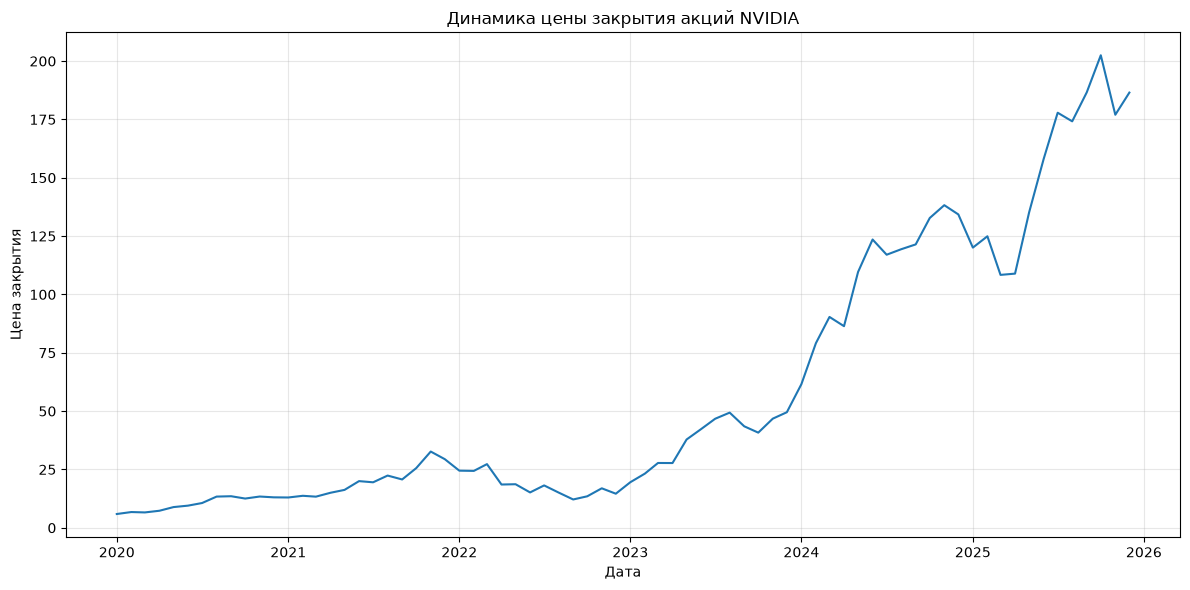

In [38]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as MultipleLocator



plt.figure(figsize=(12, 6))

plt.plot(
    data.index,
    data['Close'],
)
plt.title("Динамика цены закрытия акций NVIDIA")
plt.xlabel("Дата")
plt.ylabel("Цена закрытия")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

Видим, что за этот период акции NVIDIA многократно выросли в цене, но происходили колебания. Наиболее выраженный рост произошел в 2023-2024 годах. 

Так как ряд имеет и тренд (но это еще будет доказано), и волатильность, далее посчитаем показатели динамики цены закрытия.

### Убедимся в наличии тренда

Построим таблицу с расчетом месячных показателей динамики цены закрытия. У первой строки в колонках будет NaN из-за отсутствия предыдущего месяца для сравнения

In [69]:
import pandas as pd
import numpy as np

In [61]:
dynamics = pd.DataFrame(index=data.index)

dynamics['Цена закрытия, USD'] = data['Close']

dynamics["Абсолютный прирост, USD"] = dynamics['Цена закрытия, USD'].diff()

dynamics["Коэффициент роста"] = (
    dynamics["Цена закрытия, USD"]
    / dynamics["Цена закрытия, USD"].shift(1)
)

dynamics["Темп роста, %"] = dynamics["Коэффициент роста"] * 100

dynamics["Темп прироста, %"] = (
    dynamics["Коэффициент роста"] - 1) * 100

dynamics["Абсолютное значение 1%, USD"] = (
    dynamics["Цена закрытия, USD"].shift(1) / 100
)

dynamics.round(3).head()


,"Цена закрытия, USD","Абсолютный прирост, USD",Коэффициент роста,"Темп роста, %","Темп прироста, %","Абсолютное значение 1%, USD"
Date,,,,,,
2020-01-01,5.911,NaN,NaN,NaN,NaN,NaN
2020-02-01,6.752,0.841,1.142,114.228,14.228,0.059
2020-03-01,6.590,-0.162,0.976,97.604,-2.396,0.068
2020-04-01,7.307,0.717,1.109,110.880,10.880,0.066
2020-05-01,8.875,1.568,1.215,121.466,21.466,0.073


Небольшое пояснения каждого столбца:

- Абсолютный прирост: изменение цены в долларах по сравнению с предыдущим месяцем, отрицательное значение означает снижение цены
- Коэффициент роста: аналогично абсолютному приросту, но уже отношение цены текущего и предыдущего месяца
- Темп роста: коэффициент роста, но в процентах (больше 100 - рост, меньше - снижение цены акции)
- Темп прироста: изменение цены в процентах
- Абсолютное значение: сколько долларов составляет 1% от цены предыдущего месяца, нужен для понимания относительного прироста в процентах с реальной суммой изменения в долларах

#### Критерий Кендалла

Этого критерия не было на лекциях, но он подходит лучше предложеннных. Он сравнивает все пары наблюдений временного ряда и определяет, преобладает рост или снижение значений со временем.

Результатом проверки является коэффициент τ, принимающий значения от -1 до 1 (интерпретация значения очевидна). Также критерий является непараметрическим, то есть нам не нужно предполагать нормальное распределение цен (что удобно для финансовых данных).

$$
T_{\text{кр}} =
z_{\text{кр}}
\cdot
\sqrt{
\frac{2(2n+5)}
{9n(n-1)}
}
$$ 

$T_{\text{кр}}$ — критическое значение коэффициента Кендалла

 $z_{\text{кр}} = 1.96$ — критическое значение нормального распределения при $\alpha = 0.05$

 $n$ — число наблюдений временного ряда.

In [64]:
series = data["Close"].reset_index(drop=True)

n = len(series)

P = sum(
    series.iloc[j] > series.iloc[i]
    for i in range(n)
    for j in range(i + 1, n)
)

tau = (4 * P) / (n * (n - 1)) - 1

alpha = 0.05

z_critical = 1.96

tau_critical = z_critical * (
    (2 * (2 * n + 5)) / (9 * n * (n - 1))
) ** 0.5


print(f"Число наблюдений n = {n}")
print(f"Число возрастающих пар P = {P}")
print(f"Коэффициент Кендалла τ = {tau:.3f}")
print(f"Критическое значение Tкр = {tau_critical:.3f}")

Число наблюдений n = 72
Число возрастающих пар P = 2327
Коэффициент Кендалла τ = 0.821
Критическое значение Tкр = 0.158


Так как $|\tau| = 0.821 > T_{\text{кр}} = 0.158$, коэффициент Кендалла является статистически значимым при уровне значимости $\alpha = 0.05$. Положительное значение $\tau$ говорит о наличии выраженного восходящего тренда цены закрытия акций NVIDIA в 2020–2025 годах

**Тренд есть!** (кто бы мог подумать..)

### 1.2.1 Теперь проверяем гипотезу о линейности тренда

Проверим, можно ли описать тренд прямой. Для этого посмотрим на среднее вторых конечных разностей

$\Delta_1$ показывает изменение цены за месяц, $\Delta_2$ показывает, как изменился этот прирост. По среднему $\Delta_2$ проверим линейность тренда

In [66]:
linearity = pd.DataFrame(index=data.index)

linearity["Y"] = data["Close"]

linearity["Δ1"] = linearity["Y"].diff()
linearity["Δ2"] = linearity["Δ1"].diff()

mean_delta2 = linearity["Δ2"].mean()


print(f"Среднее значение вторых конечных разностей: {mean_delta2:.4f}")
linearity.round(3).head(10)

Среднее значение вторых конечных разностей: 0.1237


,Y,Δ1,Δ2
Date,,,
2020-01-01,5.911,NaN,NaN
2020-02-01,6.752,0.841,NaN
2020-03-01,6.590,-0.162,-1.003
2020-04-01,7.307,0.717,0.879
2020-05-01,8.875,1.568,0.851
2020-06-01,9.498,0.622,-0.946
2020-07-01,10.615,1.117,0.495
2020-08-01,13.375,2.760,1.643
2020-09-01,13.531,0.156,-2.604


Среднее вторых разностей равно $0.1237$ и близко к нулю. Проверим линейную модель и посмотрим, насколько она описывает ряд

In [70]:
trend_data = data[["Close"]]

trend_data["t"] = np.arange(1, len(trend_data) + 1)

slope, intercept = np.polyfit(
    trend_data["t"],
    trend_data["Close"],
    1
)

trend_data["Линейный тренд"] = (
    intercept + slope * trend_data["t"]
)

print(f"Уравнение линейного тренда: y = {intercept:.3f} + {slope:.3f} × t")


trend_data.head()

Уравнение линейного тренда: y = -30.193 + 2.429 × t


,Close,t,Линейный тренд
Date,,,
2020-01-01,5.91075,1,-27.763581
2020-02-01,6.75175,2,-25.334102
2020-03-01,6.59000,3,-22.904622
2020-04-01,7.30700,4,-20.475143
2020-05-01,8.87550,5,-18.045664


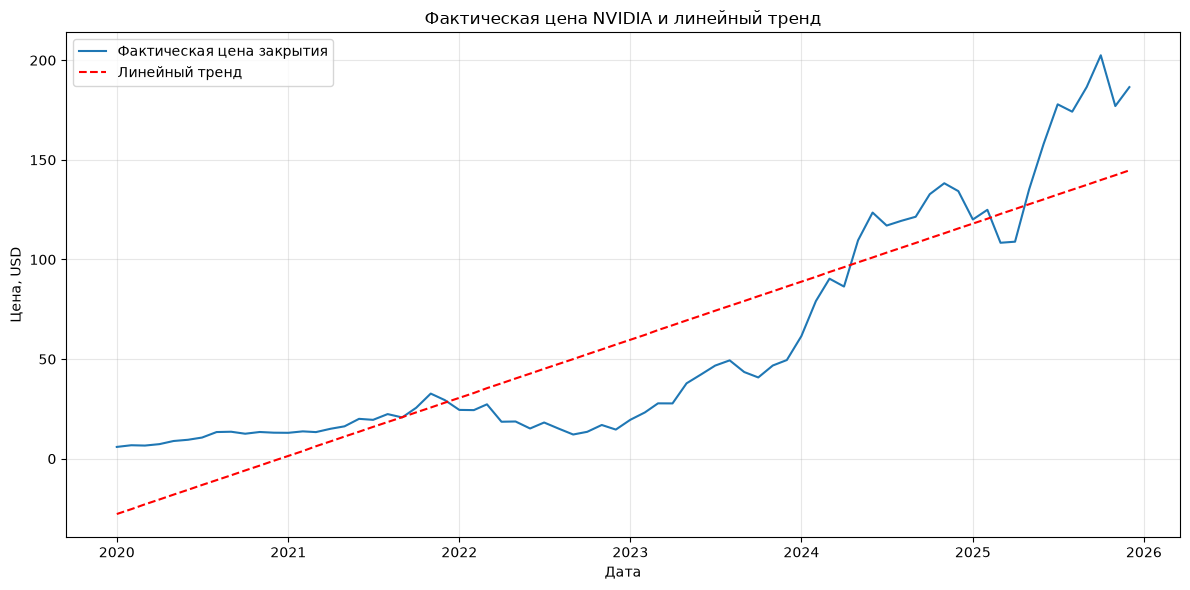

In [72]:
plt.figure(figsize=(12, 6))

plt.plot(
    trend_data.index,
    trend_data["Close"],
    label="Фактическая цена закрытия"
)

plt.plot(
    trend_data.index,
    trend_data["Линейный тренд"],
    color="red",
    linestyle="--",
    label="Линейный тренд"
)

plt.title("Фактическая цена NVIDIA и линейный тренд")
plt.xlabel("Дата")
plt.ylabel("Цена, USD")

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

Прямая показывает общий рост, но плохо описывает отдельные участки: в начале даёт отрицательные значения, а в конце отстаёт от фактической цены. Проверим нелинейную модель

### 1.2.2 Попробуем построить нелинейный тренд

In [73]:
trend_data["log_Close"] = np.log(trend_data["Close"])

exp_slope, exp_intercept = np.polyfit(
    trend_data["t"],
    trend_data["log_Close"],
    1
)

trend_data["Экспоненциальный тренд"] = np.exp(
    exp_intercept + exp_slope * trend_data["t"]
)

print(
    f"Экспоненциальный тренд: "
    f"y = exp({exp_intercept:.3f} + {exp_slope:.3f} × t)"
)

trend_data[
    ["Close", "Линейный тренд", "Экспоненциальный тренд"]
].head()

Экспоненциальный тренд: y = exp(1.856 + 0.047 × t)


,Close,Линейный тренд,Экспоненциальный тренд
Date,,,
2020-01-01,5.91075,-27.763581,6.704027
2020-02-01,6.75175,-25.334102,7.025220
2020-03-01,6.59000,-22.904622,7.361800
2020-04-01,7.30700,-20.475143,7.714507
2020-05-01,8.87550,-18.045664,8.084111


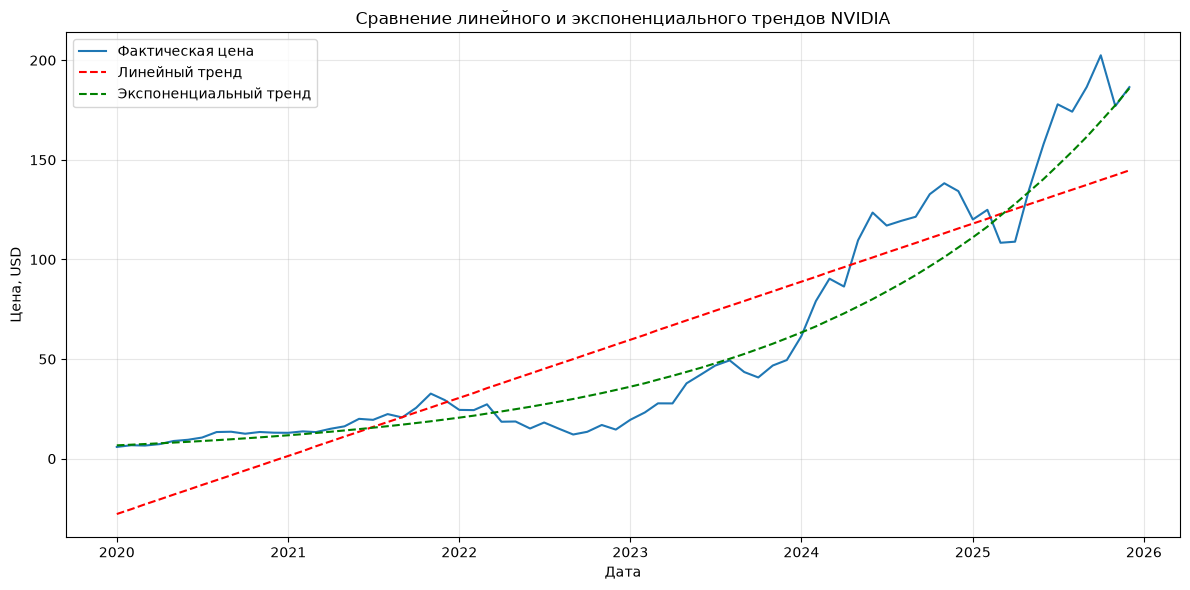

In [74]:
plt.figure(figsize=(12, 6))

plt.plot(
    trend_data.index,
    trend_data["Close"],
    label="Фактическая цена"
)

plt.plot(
    trend_data.index,
    trend_data["Линейный тренд"],
    color="red",
    linestyle="--",
    label="Линейный тренд"
)

plt.plot(
    trend_data.index,
    trend_data["Экспоненциальный тренд"],
    color="green",
    linestyle="--",
    label="Экспоненциальный тренд"
)

plt.title("Сравнение линейного и экспоненциального трендов NVIDIA")
plt.xlabel("Дата")
plt.ylabel("Цена, USD")

plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()

plt.show()

In [75]:
model_comparison = pd.DataFrame(
    index=["Линейный тренд", "Экспоненциальный тренд"]
)

actual = trend_data["Close"]

model_comparison.loc["Линейный тренд", "MAE, USD"] = (
    (actual - trend_data["Линейный тренд"]).abs().mean()
)

model_comparison.loc["Экспоненциальный тренд", "MAE, USD"] = (
    (actual - trend_data["Экспоненциальный тренд"]).abs().mean()
)

model_comparison.loc["Линейный тренд", "MAPE, %"] = (
    ((actual - trend_data["Линейный тренд"]).abs() / actual).mean() * 100
)

model_comparison.loc["Экспоненциальный тренд", "MAPE, %"] = (
    ((actual - trend_data["Экспоненциальный тренд"]).abs() / actual).mean() * 100
)

model_comparison.round(2)

,"MAE, USD","MAPE, %"
Линейный тренд,22.59,102.64
Экспоненциальный тренд,11.36,27.95


### 1.3. Проверка наличия сезонной компоненты. Составление автокорреляционной функции

In [77]:
acf_data = pd.DataFrame()

acf_data["Y"] = data["Close"]

for lag in range(1, 13):
    acf_data[f"L{lag}"] = data["Close"].shift(-lag)

acf_data.round(3).head(15)

,Y,L1,L2,L3,L4,L5,L6,L7,L8,L9,L10,L11,L12
Date,,,,,,,,,,,,,
2020-01-01,5.911,6.752,6.590,7.307,8.875,9.498,10.615,13.375,13.531,12.534,13.401,13.055,12.990
2020-02-01,6.752,6.590,7.307,8.875,9.498,10.615,13.375,13.531,12.534,13.401,13.055,12.990,13.715
2020-03-01,6.590,7.307,8.875,9.498,10.615,13.375,13.531,12.534,13.401,13.055,12.990,13.715,13.348
2020-04-01,7.307,8.875,9.498,10.615,13.375,13.531,12.534,13.401,13.055,12.990,13.715,13.348,15.009
2020-05-01,8.875,9.498,10.615,13.375,13.531,12.534,13.401,13.055,12.990,13.715,13.348,15.009,16.244
2020-06-01,9.498,10.615,13.375,13.531,12.534,13.401,13.055,12.990,13.715,13.348,15.009,16.244,20.003
2020-07-01,10.615,13.375,13.531,12.534,13.401,13.055,12.990,13.715,13.348,15.009,16.244,20.003,19.499
2020-08-01,13.375,13.531,12.534,13.401,13.055,12.990,13.715,13.348,15.009,16.244,20.003,19.499,22.385
2020-09-01,13.531,12.534,13.401,13.055,12.990,13.715,13.348,15.009,16.244,20.003,19.499,22.385,20.716


Сдвинем ряд на разное число месяцев и сравним исходные значения со сдвинутыми. Так получим автокорреляцию для каждого лага

In [78]:
acf_coefficients = []

for lag in range(1, 13):
    
    pair = acf_data[["Y", f"L{lag}"]].dropna()
    
    correlation = pair["Y"].corr(pair[f"L{lag}"])
    
    acf_coefficients.append(
        {
            "Лаг": lag,
            "Коэффициент автокорреляции": correlation
        }
    )

acf_table = pd.DataFrame(acf_coefficients)

acf_table.round(3)

,Лаг,Коэффициент автокорреляции
0,1,0.989
1,2,0.976
2,3,0.965
3,4,0.949
4,5,0.935
5,6,0.924
6,7,0.919
7,8,0.913
8,9,0.908
9,10,0.904


Наибольшая автокорреляция получилась при лаге $1$: $r_1=0.989$. К лагу $12$ она постепенно снижается до $r_{12}=0.893$, отдельного сезонного пика нет. Годовая сезонность по этому ряду не подтверждается, высокая связь соседних месяцев объясняется трендом

### 1.4. Проверка гипотезы о наличии аномальных наблюдений

Проверим каждый месяц критерием Ирвина и сравним наибольшее значение с порогом из примера

$I_i=\frac{|y_i-y_{i-1}|}{\sigma}$

Здесь $y_i$ и $y_{i-1}$ обозначают цены текущего и предыдущего месяцев, $\sigma$ обозначает стандартное отклонение ряда. Если $I_i>I_{\text{табл}}$, наблюдение считаем аномальным

In [80]:
irwin_data = pd.DataFrame(index=data.index)

irwin_data["Y"] = data["Close"]

# ddof=1 задаёт выборочное стандартное отклонение.
sigma = irwin_data["Y"].std(ddof=1)

irwin_data["Критерий Ирвина"] = (
    irwin_data["Y"].diff().abs() / sigma
)

irwin_critical = 1.3

irwin_data["Аномальное наблюдение"] = (
    irwin_data["Критерий Ирвина"] > irwin_critical
)

max_irwin_date = irwin_data["Критерий Ирвина"].idxmax()
max_irwin_value = irwin_data.loc[max_irwin_date, "Критерий Ирвина"]

print(f"Стандартное отклонение σ = {sigma:.3f}")
print(f"Наибольший критерий Ирвина: {max_irwin_value:.3f}")
print(f"Дата наблюдения: {max_irwin_date:%Y-%m}")
print(f"Критическое значение Iтабл = {irwin_critical}")

irwin_data.sort_values("Критерий Ирвина", ascending=False).head().round(3)

Стандартное отклонение σ = 57.447
Наибольший критерий Ирвина: 0.456
Дата наблюдения: 2025-05
Критическое значение Iтабл = 1.3


,Y,Критерий Ирвина,Аномальное наблюдение
Date,,,
2025-05-01,135.130,0.456,False
2025-11-01,177.000,0.444,False
2024-05-01,109.633,0.404,False
2025-06-01,157.990,0.398,False
2025-07-01,177.870,0.346,False


Максимум пришёлся на май 2025 года: $I_{\max}=0.456$, при критическом значении $I_{\text{табл}}=1.3$. Критерий ниже порога, поэтому аномальных наблюдений не обнаружено

### 1.5. Проверка гипотезы о стационарности временного ряда

In [82]:
%pip install scipy

  Using cached scipy-1.18.1-cp313-cp313-macosx_14_0_arm64.whl.metadata (62 kB)
Using cached scipy-1.18.1-cp313-cp313-macosx_14_0_arm64.whl (20.5 MB)

[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [83]:
from scipy.stats import t as student_t
from scipy.stats import f as fisher_f

alpha = 0.05

series = data["Close"]

middle = len(series) // 2

series_1 = series.iloc[:middle]

series_2 = series.iloc[middle:]

n1 = len(series_1)
n2 = len(series_2)

mean_1 = series_1.mean()
mean_2 = series_2.mean()

var_1 = series_1.var(ddof=1)
var_2 = series_2.var(ddof=1)

pooled_variance = (
    ((n1 - 1) * var_1 + (n2 - 1) * var_2)
    / (n1 + n2 - 2)
)

t_statistic = abs(mean_1 - mean_2) / (
    pooled_variance * (1 / n1 + 1 / n2)
) ** 0.5

degrees_of_freedom = n1 + n2 - 2

t_critical = student_t.ppf(1 - alpha, degrees_of_freedom)

f_statistic = max(var_1, var_2) / min(var_1, var_2)

f_lower = fisher_f.ppf(alpha / 2, n1 - 1, n2 - 1)

f_upper = fisher_f.ppf(1 - alpha / 2, n1 - 1, n2 - 1)

print(f"Среднее значение в первой части ряда: {mean_1:.3f}")
print(f"Среднее значение во второй части ряда: {mean_2:.3f}")
print(f"tрасч = {t_statistic:.3f}")
print(f"tтабл = {t_critical:.3f}")

print(f"\nДисперсия первой части ряда: {var_1:.3f}")
print(f"Дисперсия второй части ряда: {var_2:.3f}")
print(f"Fрасч = {f_statistic:.3f}")
print(f"Допустимый интервал F: от {f_lower:.3f} до {f_upper:.3f}")

Среднее значение в первой части ряда: 16.166
Среднее значение во второй части ряда: 100.800
tрасч = 9.255
tтабл = 1.667

Дисперсия первой части ряда: 42.557
Дисперсия второй части ряда: 2968.203
Fрасч = 69.747
Допустимый интервал F: от 0.510 до 1.961


Разделили ряд на две равные части: с января 2020 по декабрь 2022 года и с января 2023 по декабрь 2025 года

Средние цены: $\bar y_1=16.166$, $\bar y_2=100.800$. Статистика $t_{\text{расч}}=9.255$ выше критического значения $t_{\text{табл}}=1.667$, значит средний уровень изменился

Дисперсии равны $42.557$ и $2968.203$, а $F_{\text{расч}}=69.747$ вне допустимого интервала $[0.510; 1.961]$. Дисперсия тоже изменилась, поэтому ряд нестационарный

## 2. Расчет сезонной компоненты и оценка трендовой составляющей по мультипликативной модели

### 2.1 Расчет сезонной компоненты

In [84]:
seasonal_data = pd.DataFrame(index=data.index)

seasonal_data["Y"] = data["Close"]

seasonal_data["Скользящая средняя за 12 месяцев"] = (
    seasonal_data["Y"].rolling(window=12).mean()
)

# Для чётного окна центрируем среднее по двум соседним значениям.
seasonal_data["Центрированная скользящая средняя"] = (
    (
        seasonal_data["Скользящая средняя за 12 месяцев"]
        + seasonal_data["Скользящая средняя за 12 месяцев"].shift(-1)
    ) / 2
).shift(-5)

# В мультипликативной модели сезонный коэффициент — отношение Y к центрированной средней.
seasonal_data["Предварительный коэффициент сезонности"] = (
    seasonal_data["Y"]
    / seasonal_data["Центрированная скользящая средняя"]
)

seasonal_data.round(3).head(20)

,Y,Скользящая средняя за 12 месяцев,Центрированная скользящая средняя,Предварительный коэффициент сезонности
Date,,,,
2020-01-01,5.911,NaN,NaN,NaN
2020-02-01,6.752,NaN,NaN,NaN
2020-03-01,6.590,NaN,NaN,NaN
2020-04-01,7.307,NaN,NaN,NaN
2020-05-01,8.875,NaN,NaN,NaN
2020-06-01,9.498,NaN,NaN,NaN
2020-07-01,10.615,NaN,10.415,1.019
2020-08-01,13.375,NaN,11.000,1.216
2020-09-01,13.531,NaN,11.572,1.169


In [85]:
seasonal_data["Год"] = seasonal_data.index.year

seasonal_data["Месяц"] = seasonal_data.index.month

seasonal_data["Номер месяца в ряду"] = np.arange(1, len(seasonal_data) + 1)

seasonal_table = seasonal_data[
    [
        "Год",
        "Месяц",
        "Номер месяца в ряду",
        "Y",
        "Скользящая средняя за 12 месяцев",
        "Центрированная скользящая средняя",
        "Предварительный коэффициент сезонности"
    ]
]

seasonal_table.round(3).head(20)

,Год,Месяц,Номер месяца в ряду,Y,Скользящая средняя за 12 месяцев,Центрированная скользящая средняя,Предварительный коэффициент сезонности
Date,,,,,,,
2020-01-01,2020,1,1,5.911,NaN,NaN,NaN
2020-02-01,2020,2,2,6.752,NaN,NaN,NaN
2020-03-01,2020,3,3,6.590,NaN,NaN,NaN
2020-04-01,2020,4,4,7.307,NaN,NaN,NaN
2020-05-01,2020,5,5,8.875,NaN,NaN,NaN
2020-06-01,2020,6,6,9.498,NaN,NaN,NaN
2020-07-01,2020,7,7,10.615,NaN,10.415,1.019
2020-08-01,2020,8,8,13.375,NaN,11.000,1.216
2020-09-01,2020,9,9,13.531,NaN,11.572,1.169


In [87]:
seasonal_ratios = seasonal_data.dropna(
    subset=["Предварительный коэффициент сезонности"]
).copy()

seasonality_summary = seasonal_ratios.groupby("Месяц")[
    "Предварительный коэффициент сезонности"
].agg(["sum", "mean", "count"])

seasonality_summary.columns = [
    "Сумма",
    "Среднее",
    "Число наблюдений"
]

seasonality_sum = seasonality_summary["Среднее"].sum()

correction = (12 - seasonality_sum) / 12

seasonality_summary["Скорректированный сезонный коэффициент"] = (
    seasonality_summary["Среднее"] + correction
)

print(f"Сумма средних коэффициентов: {seasonality_sum:.6f}")
print(f"Корректировка: {correction:.6f}")

seasonality_summary.round(4)

Сумма средних коэффициентов: 11.728276
Корректировка: 0.022644


,Сумма,Среднее,Число наблюдений,Скорректированный сезонный коэффициент
Месяц,,,,
1,4.5758,0.9152,5,0.9378
2,4.8136,0.9627,5,0.9854
3,4.8948,0.9790,5,1.0016
4,4.3618,0.8724,5,0.8950
5,4.9705,0.9941,5,1.0167
6,5.1919,1.0384,5,1.0610
7,5.1956,1.0391,5,1.0618
8,5.2589,1.0518,5,1.0744
9,4.6858,0.9372,5,0.9598


Сгладим ряд 12-месячной скользящей средней и поделим цену на центрированную среднюю:

$$S_t=\frac{Y_t}{\overline{Y}_t}$$

Затем усредним коэффициенты для каждого месяца и скорректируем их, чтобы сумма была равна 12. Поправка составила $0.022644$, коэффициенты лежат от $0.8950$ до $1.0744$ и близки к единице. Выраженной сезонности нет

### 2.2. Определение тренда

В мультипликативной модели убираем сезонность делением:

$$Y_t^{(d)}=\frac{Y_t}{S_t}$$

Здесь $Y_t$ обозначает исходное значение, $S_t$ коэффициент соответствующего месяца, $Y_t^{(d)}$ цена без сезонного эффекта

In [88]:
deseasonalized_data = pd.DataFrame(index=data.index)

deseasonalized_data["Месяц"] = data.index.month

deseasonalized_data["Цена закрытия, USD"] = data["Close"]

seasonal_coefficients = (
    seasonality_summary["Скорректированный сезонный коэффициент"].to_dict()
)

deseasonalized_data["Сезонный коэффициент"] = (
    deseasonalized_data["Месяц"].map(seasonal_coefficients)
)

deseasonalized_data["Десезонализированная цена, USD"] = (
    deseasonalized_data["Цена закрытия, USD"]
    / deseasonalized_data["Сезонный коэффициент"]
)

deseasonalized_data.round(3).head(15)

,Месяц,"Цена закрытия, USD",Сезонный коэффициент,"Десезонализированная цена, USD"
Date,,,,
2020-01-01,1,5.911,0.938,6.303
2020-02-01,2,6.752,0.985,6.852
2020-03-01,3,6.590,1.002,6.579
2020-04-01,4,7.307,0.895,8.164
2020-05-01,5,8.875,1.017,8.729
2020-06-01,6,9.498,1.061,8.951
2020-07-01,7,10.615,1.062,9.997
2020-08-01,8,13.375,1.074,12.448
2020-09-01,9,13.531,0.960,14.097


Для каждого месяца разделили цену закрытия на сезонный коэффициент. Полученный ряд используем для оценки тренда без сезонной составляющей

In [89]:
deseasonalized_data["t"] = np.arange(1, len(deseasonalized_data) + 1)

c2, c1, c0 = np.polyfit(
    deseasonalized_data["t"],
    deseasonalized_data["Десезонализированная цена, USD"],
    2
)

deseasonalized_data["Трендовое значение, USD"] = (
    c2 * deseasonalized_data["t"] ** 2
    + c1 * deseasonalized_data["t"]
    + c0
)

print(
    f"Полиномиальный тренд: "
    f"y = {c2:.4f} × t² + {c1:.4f} × t + {c0:.4f}"
)

deseasonalized_data[
    [
        "Цена закрытия, USD",
        "Сезонный коэффициент",
        "Десезонализированная цена, USD",
        "t",
        "Трендовое значение, USD"
    ]
].round(3).head(15)

Полиномиальный тренд: y = 0.0589 × t² + -1.8769 × t + 23.0402


,"Цена закрытия, USD",Сезонный коэффициент,"Десезонализированная цена, USD",t,"Трендовое значение, USD"
Date,,,,,
2020-01-01,5.911,0.938,6.303,1,21.222
2020-02-01,6.752,0.985,6.852,2,19.522
2020-03-01,6.590,1.002,6.579,3,17.939
2020-04-01,7.307,0.895,8.164,4,16.474
2020-05-01,8.875,1.017,8.729,5,15.127
2020-06-01,9.498,1.061,8.951,6,13.897
2020-07-01,10.615,1.062,9.997,7,12.786
2020-08-01,13.375,1.074,12.448,8,11.791
2020-09-01,13.531,0.960,14.097,9,10.915


По десезонализированному ряду оценили полином второй степени:

$$\hat{Y}_t=0.0589t^2-1.8769t+23.0402$$

Положительный коэффициент при $t^2$ отражает ускорение роста к концу периода. Точность модели дальше проверим по ошибкам и остаткам

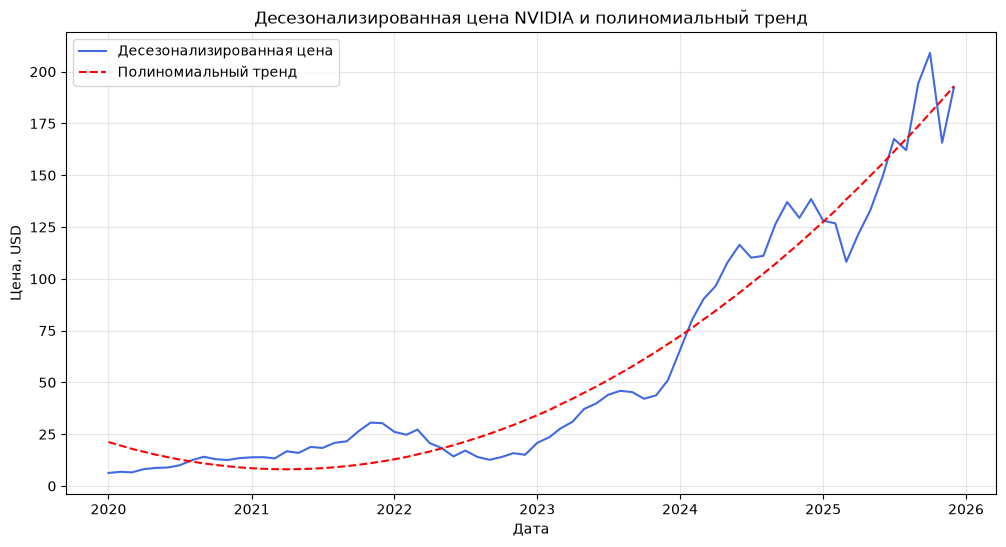

In [90]:
plt.figure(figsize=(12, 6))

plt.plot(
    deseasonalized_data.index,
    deseasonalized_data["Десезонализированная цена, USD"],
    label="Десезонализированная цена",
    color="royalblue"
)

plt.plot(
    deseasonalized_data.index,
    deseasonalized_data["Трендовое значение, USD"],
    label="Полиномиальный тренд",
    color="red",
    linestyle="--"
)

plt.title("Десезонализированная цена NVIDIA и полиномиальный тренд")
plt.xlabel("Дата")
plt.ylabel("Цена, USD")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

Полином отражает общий ускоряющийся рост, но фактические цены заметно колеблются вокруг линии. Поэтому отдельно оценим ошибки и остатки

### 2.3. Определение качества модели и расчет ошибок

In [91]:
quality_data = pd.DataFrame(index=data.index)

quality_data["Год"] = data.index.year

quality_data["Месяц"] = data.index.month

quality_data["Номер месяца в ряду"] = np.arange(1, len(data) + 1)

quality_data["Фактическая цена, USD"] = data["Close"]

quality_data["Сезонный коэффициент"] = (
    deseasonalized_data["Сезонный коэффициент"]
)

quality_data["Трендовое значение T, USD"] = (
    deseasonalized_data["Трендовое значение, USD"]
)

quality_data["Расчётная цена T × S, USD"] = (
    quality_data["Трендовое значение T, USD"]
    * quality_data["Сезонный коэффициент"]
)

quality_data["Коэффициент ошибки E"] = (
    quality_data["Фактическая цена, USD"]
    / quality_data["Расчётная цена T × S, USD"]
)

quality_data.round(3).head(15)

,Год,Месяц,Номер месяца в ряду,"Фактическая цена, USD",Сезонный коэффициент,"Трендовое значение T, USD","Расчётная цена T × S, USD",Коэффициент ошибки E
Date,,,,,,,,
2020-01-01,2020,1,1,5.911,0.938,21.222,19.902,0.297
2020-02-01,2020,2,2,6.752,0.985,19.522,19.236,0.351
2020-03-01,2020,3,3,6.590,1.002,17.939,17.968,0.367
2020-04-01,2020,4,4,7.307,0.895,16.474,14.744,0.496
2020-05-01,2020,5,5,8.875,1.017,15.127,15.380,0.577
2020-06-01,2020,6,6,9.498,1.061,13.897,14.746,0.644
2020-07-01,2020,7,7,10.615,1.062,12.786,13.575,0.782
2020-08-01,2020,8,8,13.375,1.074,11.791,12.669,1.056
2020-09-01,2020,9,9,13.531,0.960,10.915,10.476,1.292


Коэффициент $E$ сравнивает фактическую цену с расчётной: чем он ближе к единице, тем лучше совпадение. В начале модель заметно завышает цену, поэтому дальше проверим ошибки и остатки

### 2.4. Проверка адекватности и качества построенной модели тренда

In [92]:
residuals_data = pd.DataFrame(index=data.index)

residuals_data["Десезонализированная цена, Yнабл, USD"] = (
    deseasonalized_data["Десезонализированная цена, USD"]
)

residuals_data["Расчётное значение Yрасч, USD"] = (
    deseasonalized_data["Трендовое значение, USD"]
)

residuals_data["Остатки e, USD"] = (
    residuals_data["Десезонализированная цена, Yнабл, USD"]
    - residuals_data["Расчётное значение Yрасч, USD"]
)

residuals_data.round(3).head(15)

,"Десезонализированная цена, Yнабл, USD","Расчётное значение Yрасч, USD","Остатки e, USD"
Date,,,
2020-01-01,6.303,21.222,-14.919
2020-02-01,6.852,19.522,-12.670
2020-03-01,6.579,17.939,-11.360
2020-04-01,8.164,16.474,-8.310
2020-05-01,8.729,15.127,-6.398
2020-06-01,8.951,13.897,-4.946
2020-07-01,9.997,12.786,-2.788
2020-08-01,12.448,11.791,0.657
2020-09-01,14.097,10.915,3.182


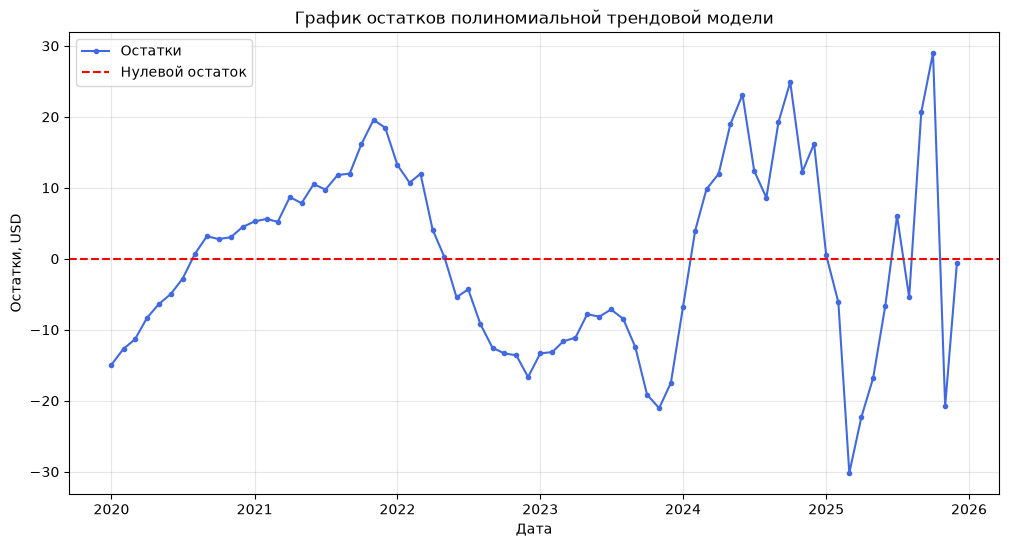

In [93]:
plt.figure(figsize=(12, 6))

plt.plot(
    residuals_data.index,
    residuals_data["Остатки e, USD"],
    color="royalblue",
    marker="o",
    markersize=3,
    label="Остатки"
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Нулевой остаток"
)

plt.title("График остатков полиномиальной трендовой модели")
plt.xlabel("Дата")
plt.ylabel("Остатки, USD")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

Остатки идут длинными участками одного знака, значит модель оставляет в них структуру. Проверим это критериями

### 2.4.1. Проверка математического ожидания ряда остатков

Если $|t_{\text{расч}}|<t_{\text{табл}}$, среднее остатков считаем близким к нулю и систематического смещения не обнаруживаем

In [94]:
alpha = 0.05

residuals = residuals_data["Остатки e, USD"]

n_residuals = len(residuals)

mean_residual = residuals.mean()

sigma_residual = residuals.std(ddof=1)

t_residual = abs(mean_residual) / (
    sigma_residual / n_residuals ** 0.5
)

df_residuals = n_residuals - 1

t_critical_residual = student_t.ppf(1 - alpha, df_residuals)

print(f"Среднее значение остатков: {mean_residual:.6f}")
print(f"Стандартное отклонение остатков σe: {sigma_residual:.3f}")
print(f"tрасч: {t_residual:.6f}")
print(f"tтабл: ±{t_critical_residual:.3f}")

Среднее значение остатков: -0.000000
Стандартное отклонение остатков σe: 13.145
tрасч: 0.000000
tтабл: ±1.667


Критические области: $(-\infty; -1.667)$ и $(1.667; +\infty)$. Получили $t_{\text{расч}}=0$, он вне этих областей. Принимаем $H_0: \mu_e=0$, среднее остатков близко к нулю

### 2.4.2. Проверка случайности ряда остатков проведем методом серий

Серии это последовательности остатков одного знака. Если знаки чередуются случайно, число серий не должно сильно отличаться от ожидаемого

$H_0$: остатки случайны. При $z_{\text{расч}}<z_{\text{табл}}=1.96$ гипотезу принимаем

In [95]:
nonzero_residuals = residuals[
    residuals.abs() > 1e-10
]

residual_signs = np.where(nonzero_residuals > 0, 1, -1)

n_positive = (residual_signs == 1).sum()

n_negative = (residual_signs == -1).sum()

runs = 1 + np.sum(residual_signs[1:] != residual_signs[:-1])

expected_runs = (
    1
    + (2 * n_positive * n_negative)
    / (n_positive + n_negative)
)

variance_runs = (
    2
    * n_positive
    * n_negative
    * (2 * n_positive * n_negative - n_positive - n_negative)
    / (
        (n_positive + n_negative) ** 2
        * (n_positive + n_negative - 1)
    )
)

std_runs = variance_runs ** 0.5

z_runs = abs(runs - expected_runs) / std_runs

z_critical_runs = 1.96

print(f"Число положительных остатков: {n_positive}")
print(f"Число отрицательных остатков: {n_negative}")
print(f"Фактическое число серий: {runs}")
print(f"Ожидаемое число серий: {expected_runs:.3f}")
print(f"zрасч: {z_runs:.3f}")
print(f"zтабл: {z_critical_runs}")

Число положительных остатков: 37
Число отрицательных остатков: 35
Фактическое число серий: 9
Ожидаемое число серий: 36.972
zрасч: 6.645
zтабл: 1.96


Положительных остатков 37, отрицательных 35. Получили $R_{\text{факт}}=9$ при ожидаемом $R_{\text{ожид}}=36.972$

$z_{\text{расч}}=6.645>z_{\text{табл}}=1.96$, поэтому $H_0$ отвергаем. Остатки неслучайны, в модели осталась неучтённая структура

### 2.4.3. Проверка независимости значений ряда остатков проведем методом Дарбина-Уотсона

Критерий Дарбина-Уотсона проверяет связь соседних остатков. При независимости $DW$ близок к 2: значения ниже 2 указывают на положительную автокорреляцию, значения выше 2 указывают на отрицательную

$H_0$: остатки независимы

$$DW=\frac{\sum_{t=2}^{n}(e_t-e_{t-1})^2}{\sum_{t=1}^{n}e_t^2}$$

In [96]:
residual_values = residuals_data["Остатки e, USD"].to_numpy()

# DW сопоставляет разности соседних остатков с их общим разбросом.
dw_numerator = np.sum(
    (residual_values[1:] - residual_values[:-1]) ** 2
)

dw_denominator = np.sum(residual_values ** 2)

durbin_watson = dw_numerator / dw_denominator

print(f"Критерий Дарбина—Уотсона: {durbin_watson:.3f}")

Критерий Дарбина—Уотсона: 0.503


Получили $DW=0.503$, это намного меньше 2. Значит, есть положительная автокорреляция: соседние ошибки связаны. Гипотезу о независимости отвергаем

### 2.4.4. Проверка гипотезы о нормальном распределении остатков

Проверим, похожи ли остатки на нормальное распределение, с помощью критерия $R/S$

$H_0$: остатки распределены нормально

$$\left(\frac{R}{S}\right)_{\text{расч}}=\frac{e_{\max}-e_{\min}}{\sigma_e}$$

In [99]:
residual_max = residuals.max()

residual_min = residuals.min()

residual_range = residual_max - residual_min

rs_statistic = residual_range / sigma_residual

print(f"Максимальный остаток emax: {residual_max:.3f}")
print(f"Минимальный остаток emin: {residual_min:.3f}")
print(f"Размах R: {residual_range:.3f}")
print(f"Стандартное отклонение σe: {sigma_residual:.3f}")
print(f"(R/S)расч: {rs_statistic:.3f}")

Максимальный остаток emax: 29.003
Минимальный остаток emin: -30.174
Размах R: 59.177
Стандартное отклонение σe: 13.145
(R/S)расч: 4.502


In [100]:
alpha_rs = 0.005

# Фиксированный seed делает моделируемые границы R/S воспроизводимыми.
random_generator = np.random.default_rng(seed=42)

n_simulations = 100_000

simulated_samples = random_generator.normal(
    size=(n_simulations, n_residuals)
)

simulated_rs = (
    (simulated_samples.max(axis=1) - simulated_samples.min(axis=1))
    / simulated_samples.std(axis=1, ddof=1)
)

rs_lower = np.quantile(simulated_rs, alpha_rs / 2)

rs_upper = np.quantile(simulated_rs, 1 - alpha_rs / 2)

print(f"Нижняя критическая граница: {rs_lower:.3f}")
print(f"Верхняя критическая граница: {rs_upper:.3f}")
print(f"(R/S)расч: {rs_statistic:.3f}")

Нижняя критическая граница: 3.741
Верхняя критическая граница: 6.430
(R/S)расч: 4.502


Для $n=72$ и $\alpha=0.005$ критические границы равны:

$$3.741\leq (R/S)_{\text{расч}}\leq 6.430$$

Получили $(R/S)_{\text{расч}}=4.502$, значение внутри интервала. Гипотезу о нормальном распределении остатков принимаем

### 2.4.5. Проверка гипотезы о постоянстве дисперсии остатков

Проверим, постоянна ли дисперсия остатков, сравнив две равные части ряда

$H_0$: дисперсии двух частей одинаковы

In [101]:
middle_residuals = len(residuals) // 2

residuals_1 = residuals.iloc[:middle_residuals]

residuals_2 = residuals.iloc[middle_residuals:]

n_residuals_1 = len(residuals_1)
n_residuals_2 = len(residuals_2)

var_residuals_1 = residuals_1.var(ddof=1)

var_residuals_2 = residuals_2.var(ddof=1)

f_residuals = max(var_residuals_1, var_residuals_2) / min(
    var_residuals_1,
    var_residuals_2
)

f_residuals_lower = fisher_f.ppf(
    alpha / 2,
    n_residuals_1 - 1,
    n_residuals_2 - 1
)

f_residuals_upper = fisher_f.ppf(
    1 - alpha / 2,
    n_residuals_1 - 1,
    n_residuals_2 - 1
)

print(f"Дисперсия первой половины остатков: {var_residuals_1:.3f}")
print(f"Дисперсия второй половины остатков: {var_residuals_2:.3f}")
print(f"Fрасч: {f_residuals:.3f}")
print(
    f"Допустимый интервал F: "
    f"от {f_residuals_lower:.3f} до {f_residuals_upper:.3f}"
)

Дисперсия первой половины остатков: 106.076
Дисперсия второй половины остатков: 240.676
Fрасч: 2.269
Допустимый интервал F: от 0.510 до 1.961


Дисперсии половин равны $106.076$ и $240.676$. Получили $F_{\text{расч}}=2.269$, это выше допустимого интервала $[0.510; 1.961]$. $H_0$ отвергаем: разброс остатков меняется во времени

## 3. Расчёт ошибок и оценка точности модели

Сравним расчётные и фактические цены по четырём показателям:

$$MAD=\frac{1}{n}\sum_{t=1}^{n}|Y_t-\hat{Y}_t|$$

$$MAPE=\frac{100\%}{n}\sum_{t=1}^{n}\left|\frac{Y_t-\hat{Y}_t}{Y_t}\right|$$

$$MSE=\frac{1}{n}\sum_{t=1}^{n}(Y_t-\hat{Y}_t)^2$$

$$MPE=\frac{100\%}{n}\sum_{t=1}^{n}\frac{Y_t-\hat{Y}_t}{Y_t}$$

In [103]:
actual_values = quality_data["Фактическая цена, USD"]

predicted_values = quality_data["Расчётная цена T × S, USD"]

errors = actual_values - predicted_values

mad = errors.abs().mean()

mape = (errors.abs() / actual_values).mean() * 100

mpe = (errors / actual_values).mean() * 100

mse = (errors ** 2).mean()

accuracy_metrics = pd.DataFrame(
    {
        "MAD, USD": [mad],
        "MAPE, %": [mape],
        "MSE, USD²": [mse],
        "MPE, %": [mpe]
    },
    index=["Полиномиальная мультипликативная модель"]
)

accuracy_metrics.round(2)

,"MAD, USD","MAPE, %","MSE, USD²","MPE, %"
Полиномиальная мультипликативная модель,11.15,41.04,168.7,-11.62


Средняя абсолютная ошибка $MAD=11.15$ USD, средняя относительная ошибка $MAPE=41.04\%$. Отрицательный $MPE=-11.62\%$ означает, что модель в среднем завышает цену. Точность модели низкая

## 4. Прогноз на шестой год

Для прогноза продолжим полиномиальный тренд и применим коэффициент соответствующего месяца:

$$\hat{Y}_{t}=T_t\times S_t$$

In [104]:
forecast_dates = pd.date_range(
    start="2026-01-01",
    periods=12,
    freq="MS"
)

forecast_t = np.arange(
    len(data) + 1,
    len(data) + 13
)

forecast_data = pd.DataFrame(index=forecast_dates)

forecast_data["Месяц"] = forecast_data.index.month

forecast_data["t"] = forecast_t

forecast_data["Прогноз тренда T, USD"] = (
    c2 * forecast_data["t"] ** 2
    + c1 * forecast_data["t"]
    + c0
)

forecast_data["Сезонный коэффициент S"] = (
    forecast_data["Месяц"].map(seasonal_coefficients)
)

forecast_data["Прогноз цены T × S, USD"] = (
    forecast_data["Прогноз тренда T, USD"]
    * forecast_data["Сезонный коэффициент S"]
)

forecast_data.round(2)

,Месяц,t,"Прогноз тренда T, USD",Сезонный коэффициент S,"Прогноз цены T × S, USD"
2026-01-01,1,73,199.65,0.94,187.23
2026-02-01,2,74,206.42,0.99,203.40
2026-03-01,3,75,213.32,1.00,213.66
2026-04-01,4,76,220.33,0.89,197.19
2026-05-01,5,77,227.45,1.02,231.26
2026-06-01,6,78,234.70,1.06,249.02
2026-07-01,7,79,242.06,1.06,257.01
2026-08-01,8,80,249.54,1.07,268.11
2026-09-01,9,81,257.14,0.96,246.80
2026-10-01,10,82,264.86,0.97,256.56


Модель даёт рост от $187.23$ USD в январе до пика $291.30$ USD в ноябре. При $MAPE=41.04\%$ эти значения стоит считать ориентиром, а не точной оценкой

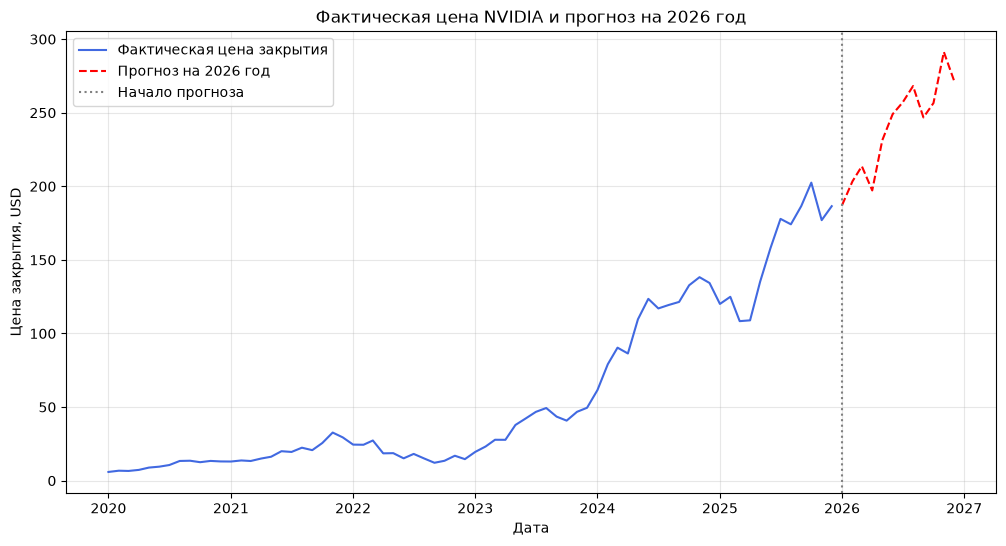

In [106]:
plt.figure(figsize=(12, 6))

plt.plot(
    data.index,
    data["Close"],
    color="royalblue",
    label="Фактическая цена закрытия"
)

plt.plot(
    forecast_data.index,
    forecast_data["Прогноз цены T × S, USD"],
    color="red",
    linestyle="--",
    label="Прогноз на 2026 год"
)

plt.axvline(
    x=pd.Timestamp("2026-01-01"),
    color="gray",
    linestyle=":",
    label="Начало прогноза"
)

plt.title("Фактическая цена NVIDIA и прогноз на 2026 год")
plt.xlabel("Дата")
plt.ylabel("Цена закрытия, USD")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [107]:
real_2026 = yf.download(
    "NVDA",
    start="2026-01-01",
    end="2026-10-01",
    interval="1mo",
    auto_adjust=False,
    progress=False
)

# yfinance иногда возвращает многоуровневые названия столбцов.
if isinstance(real_2026.columns, pd.MultiIndex):
    real_2026.columns = real_2026.columns.get_level_values(0)

real_2026 = real_2026[["Close"]].copy()

real_2026.index = pd.to_datetime(real_2026.index).tz_localize(None)

real_2026 = real_2026.rename(
    columns={"Close": "Фактическая цена 2026, USD"}
)

real_2026.round(2)

Price,"Фактическая цена 2026, USD"
Date,
2026-01-01,191.13
2026-02-01,177.19
2026-03-01,174.40
2026-04-01,199.57
2026-05-01,211.14
2026-06-01,200.09
2026-07-01,200.75
2026-08-01,220.78
2026-09-01,228.38


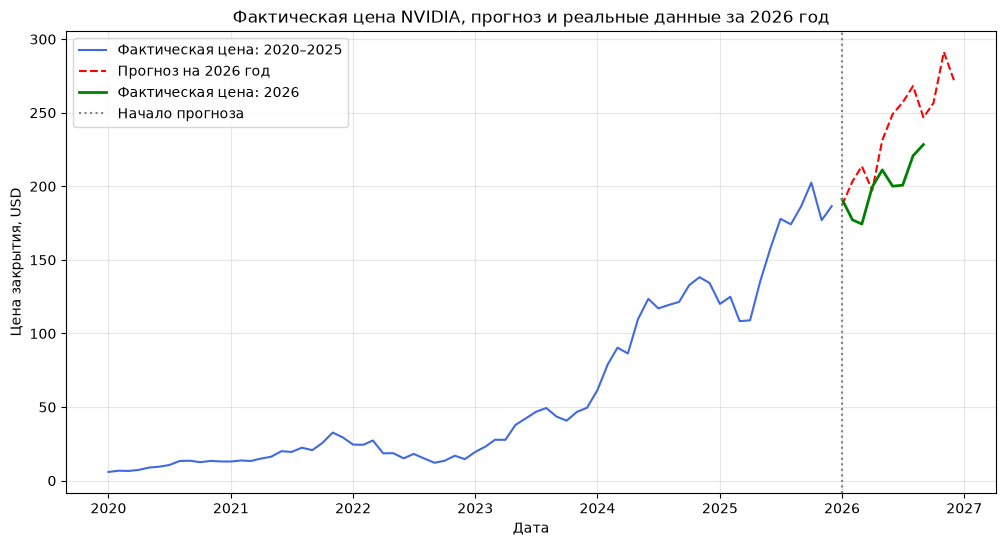

In [109]:
plt.figure(figsize=(12, 6))

plt.plot(
    data.index,
    data["Close"],
    color="royalblue",
    label="Фактическая цена: 2020–2025"
)

plt.plot(
    forecast_data.index,
    forecast_data["Прогноз цены T × S, USD"],
    color="red",
    linestyle="--",
    label="Прогноз на 2026 год"
)

plt.plot(
    real_2026.index,
    real_2026["Фактическая цена 2026, USD"],
    color="green",
    linewidth=2,
    label="Фактическая цена: 2026"
)

plt.axvline(
    x=pd.Timestamp("2026-01-01"),
    color="gray",
    linestyle=":",
    label="Начало прогноза"
)

plt.title("Фактическая цена NVIDIA, прогноз и реальные данные за 2026 год")
plt.xlabel("Дата")
plt.ylabel("Цена закрытия, USD")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [110]:
forecast_vs_actual = forecast_data[
    ["Прогноз цены T × S, USD"]
].join(
    real_2026,
    how="inner"
)

forecast_vs_actual["Ошибка прогноза, USD"] = (
    forecast_vs_actual["Прогноз цены T × S, USD"]
    - forecast_vs_actual["Фактическая цена 2026, USD"]
)

forecast_vs_actual["Абсолютная ошибка, USD"] = (
    forecast_vs_actual["Ошибка прогноза, USD"].abs()
)

forecast_vs_actual["Абсолютная процентная ошибка, %"] = (
    forecast_vs_actual["Абсолютная ошибка, USD"]
    / forecast_vs_actual["Фактическая цена 2026, USD"]
    * 100
)

forecast_vs_actual.round(2)

,"Прогноз цены T × S, USD","Фактическая цена 2026, USD","Ошибка прогноза, USD","Абсолютная ошибка, USD","Абсолютная процентная ошибка, %"
2026-01-01,187.23,191.13,-3.90,3.90,2.04
2026-02-01,203.40,177.19,26.21,26.21,14.79
2026-03-01,213.66,174.40,39.26,39.26,22.51
2026-04-01,197.19,199.57,-2.38,2.38,1.19
2026-05-01,231.26,211.14,20.12,20.12,9.53
2026-06-01,249.02,200.09,48.93,48.93,24.46
2026-07-01,257.01,200.75,56.26,56.26,28.03
2026-08-01,268.11,220.78,47.33,47.33,21.44
2026-09-01,246.80,228.38,18.42,18.42,8.07


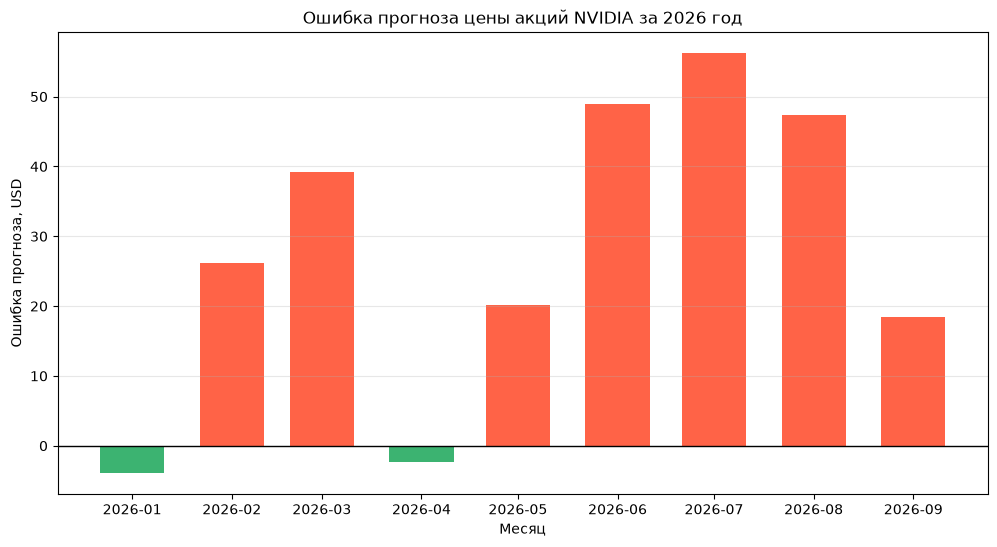

In [111]:
plt.figure(figsize=(12, 6))

bar_colors = np.where(
    forecast_vs_actual["Ошибка прогноза, USD"] >= 0,
    "tomato",
    "mediumseagreen"
)

plt.bar(
    forecast_vs_actual.index,
    forecast_vs_actual["Ошибка прогноза, USD"],
    width=20,
    color=bar_colors
)

plt.axhline(
    y=0,
    color="black",
    linewidth=1
)

plt.title("Ошибка прогноза цены акций NVIDIA за 2026 год")
plt.xlabel("Месяц")
plt.ylabel("Ошибка прогноза, USD")

plt.grid(axis="y", alpha=0.3)

plt.show()

## Общий вывод

Ряд за 2020–2025 годы растёт и нестационарен. Критерий Кендалла подтвердил восходящий тренд ($\tau=0.821$), выраженной годовой сезонности не обнаружено

Для прогноза построили мультипликативную модель с полиномиальным трендом:

$$\hat{Y}_t=\left(0.0589t^2-1.8769t+23.0402\right)S_t$$

Проверки остатков показали нулевое среднее и согласие с нормальным распределением, но остатки неслучайны, зависимы и имеют меняющуюся дисперсию

$MAPE=41.04\%$, поэтому точность модели ограничена. На доступных месяцах 2026 года модель в основном завышала цены. Прогноз показывает общее направление, но не даёт точной оценки будущих значений

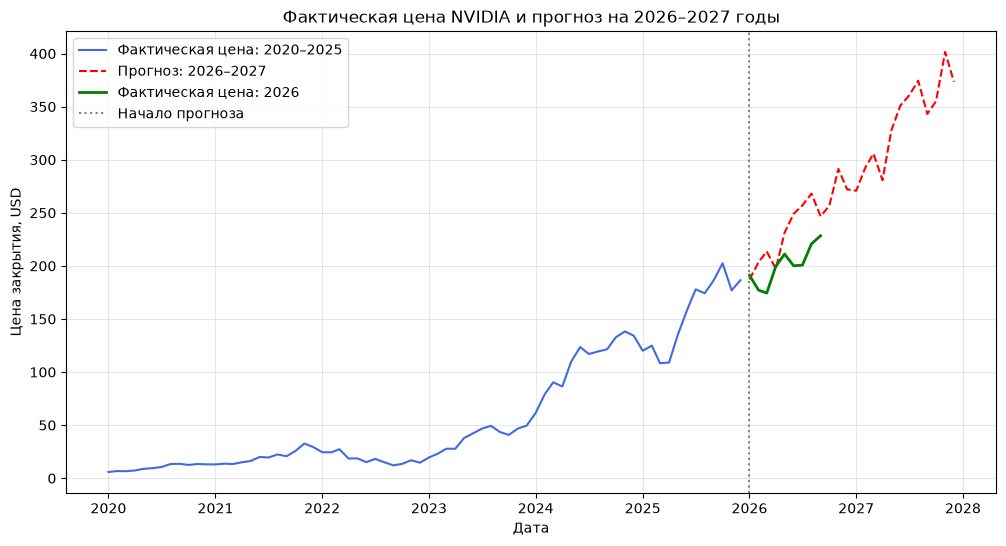

In [112]:
forecast_2y_dates = pd.date_range(
    start="2026-01-01",
    periods=24,
    freq="MS"
)

forecast_2y_t = np.arange(
    len(data) + 1,
    len(data) + 25
)

forecast_2y_data = pd.DataFrame(index=forecast_2y_dates)

forecast_2y_data["Месяц"] = forecast_2y_data.index.month

forecast_2y_data["t"] = forecast_2y_t

forecast_2y_data["Прогноз тренда T, USD"] = (
    c2 * forecast_2y_data["t"] ** 2
    + c1 * forecast_2y_data["t"]
    + c0
)

forecast_2y_data["Сезонный коэффициент S"] = (
    forecast_2y_data["Месяц"].map(seasonal_coefficients)
)

forecast_2y_data["Прогноз цены T × S, USD"] = (
    forecast_2y_data["Прогноз тренда T, USD"]
    * forecast_2y_data["Сезонный коэффициент S"]
)

plt.figure(figsize=(12, 6))

plt.plot(
    data.index,
    data["Close"],
    color="royalblue",
    label="Фактическая цена: 2020–2025"
)

plt.plot(
    forecast_2y_data.index,
    forecast_2y_data["Прогноз цены T × S, USD"],
    color="red",
    linestyle="--",
    markersize=3,
    label="Прогноз: 2026–2027"
)

plt.plot(
    real_2026.index,
    real_2026["Фактическая цена 2026, USD"],
    color="green",
    linewidth=2,
    label="Фактическая цена: 2026"
)

plt.axvline(
    x=pd.Timestamp("2026-01-01"),
    color="gray",
    linestyle=":",
    label="Начало прогноза"
)

plt.title("Фактическая цена NVIDIA и прогноз на 2026–2027 годы")
plt.xlabel("Дата")
plt.ylabel("Цена закрытия, USD")

plt.legend()
plt.grid(alpha=0.3)

plt.show()